# P08. SQL avançado sobre o Censo Escolar e o Ideb

Quero montar um banco relacional com dados reais da escola pública brasileira e usar SQL para responder uma pergunta: o que distingue, no papel, as escolas de Ideb alto das de Ideb baixo? Uso o Censo Escolar 2025 (escola, matrícula, turma, docente, gestor e curso técnico), o Ideb 2025 por escola e as taxas de rendimento 2025, tudo do INEP e ligado pelo código da escola. Para o banco caber em um SQLite e o recorte ficar comparável, fico com Minas Gerais e Ceará.

O caminho tem quatro partes: preparar as tabelas e montar o banco, juntar tabelas e criar uma view, comparar as escolas por grupo de Ideb e testar uma transação. No fim, três gráficos resumem o que encontrei. A pergunta é sobre os anos iniciais do ensino fundamental, a etapa com mais escolas no recorte.

In [1]:
import sqlite3
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

import estilo

estilo.aplica_tema()

RAIZ = Path.cwd().parent
DADOS = RAIZ / "data"
UFS = ["MG", "CE"]

## Os arquivos

Os cinco arquivos vêm do INEP e eu os baixei para a pasta `data/`, que fica fora do Git. O servidor do INEP usa um certificado que a biblioteca `requests` do Python não valida, então o download é manual: o notebook só confere se os zips estão lá e extrai cada um uma vez. Os endereços estão no README.

In [2]:
ZIPS = [
    "microdados_censo_escolar_2025_.zip",
    "divulgacao_anos_iniciais_escolas_2025.zip",
    "divulgacao_anos_finais_escolas_2025.zip",
    "divulgacao_ensino_medio_escolas_2025.zip",
    "tx_rend_escolas_2025.zip",
]
faltam = [z for z in ZIPS if not (DADOS / z).exists()]
assert not faltam, f"baixe antes para a pasta data/: {faltam}"

for nome in ZIPS:
    destino = DADOS / Path(nome).stem
    if destino.exists():
        continue
    with zipfile.ZipFile(DADOS / nome) as z:
        z.extractall(destino)

CENSO = DADOS / "microdados_censo_escolar_2025_" / "microdados_censo_escolar_2025_v2" / "dados"
REND = DADOS / "tx_rend_escolas_2025" / "tx_rend_escolas_2025" / "tx_rend_escolas_2025.xlsx"


def caminho_ideb(nivel):
    pasta = f"divulgacao_{nivel}_escolas_2025"
    return DADOS / pasta / pasta / f"{pasta}.xlsx"


sorted(p.name for p in CENSO.glob("*.csv"))

['Tabela_Curso_Tecnico_2025_V2.csv',
 'Tabela_Docente_2025_V2.csv',
 'Tabela_Escola_2025_V2.csv',
 'Tabela_Gestor_Escolar_2025_v2.csv',
 'Tabela_Matricula_2025_V2.csv',
 'Tabela_Turma_2025_V2.csv']

## Censo Escolar

A tabela de escolas tem uma linha por escola e 290 colunas. Fico com 27: a identificação, o tipo de escola, a infraestrutura, a tecnologia e a equipe. O arquivo é separado por ponto e vírgula e está em latin-1, e eu leio só as colunas que uso.

In [3]:
COLS_ESCOLA = [
    "CO_ENTIDADE", "NO_ENTIDADE", "SG_UF", "CO_MUNICIPIO", "NO_MUNICIPIO",
    "TP_DEPENDENCIA", "TP_LOCALIZACAO", "TP_LOCALIZACAO_DIFERENCIADA", "TP_SITUACAO_FUNCIONAMENTO",
    "IN_AGUA_REDE_PUBLICA", "IN_ESGOTO_REDE_PUBLICA", "IN_BIBLIOTECA", "IN_BIBLIOTECA_SALA_LEITURA",
    "IN_LABORATORIO_CIENCIAS", "IN_LABORATORIO_INFORMATICA", "IN_QUADRA_ESPORTES",
    "IN_INTERNET", "IN_BANDA_LARGA", "IN_ALIMENTACAO", "IN_COMPUTADOR",
    "QT_SALAS_UTILIZADAS", "QT_DESKTOP_ALUNO", "QT_COMP_PORTATIL_ALUNO", "QT_TABLET_ALUNO",
    "QT_PROF_BIBLIOTECARIO", "QT_PROF_PSICOLOGO", "QT_PROF_COORDENADOR",
]


def ler_censo(arquivo, colunas):
    return pd.read_csv(CENSO / arquivo, sep=";", encoding="latin-1", usecols=colunas, low_memory=False)


escola_br = ler_censo("Tabela_Escola_2025_V2.csv", COLS_ESCOLA)
print("escolas no Brasil:", estilo.num(escola_br.shape[0], 0), "| código único:", escola_br["CO_ENTIDADE"].is_unique)
escola_br["TP_SITUACAO_FUNCIONAMENTO"].value_counts().sort_index()

escolas no Brasil: 214.192 | código único: True


TP_SITUACAO_FUNCIONAMENTO
1    180540
2     29780
3      3872
Name: count, dtype: int64

In [4]:
escola = escola_br[escola_br["SG_UF"].isin(UFS)].reset_index(drop=True)
escola["SG_UF"].value_counts()

SG_UF
MG    24069
CE    10122
Name: count, dtype: int64

O Brasil tem 214.192 escolas no arquivo, cada uma com um código único (`CO_ENTIDADE`), que é a chave que liga todas as tabelas. Desse total, 180.540 estão em atividade, 29.780 estão paralisadas e 3.872 foram extintas no ano do Censo. O recorte de Minas e Ceará tem 34.191 escolas, 24.069 mineiras e 10.122 cearenses.

### As outras tabelas do Censo

Matrícula, turma, docente e gestor não são listas de alunos, turmas e professores. Cada uma tem uma linha por escola, com quantidades por etapa (`QT_MAT_...`, `QT_TUR_...`, `QT_DOC_...`, `QT_GEST_...`), então o join entre elas e a escola é de um para um. A exceção é o curso técnico, que tem uma linha por curso dentro da escola. Filtro cada tabela pelas escolas que estão no recorte, e não pela UF, para que nenhuma linha aponte para uma escola que não está no banco.

In [5]:
TABELAS = {
    "matricula": ("Tabela_Matricula_2025_V2.csv", [
        "CO_ENTIDADE", "QT_MAT_BAS", "QT_MAT_INF", "QT_MAT_FUND", "QT_MAT_FUND_AI",
        "QT_MAT_FUND_AF", "QT_MAT_MED", "QT_MAT_PROF", "QT_MAT_EJA", "QT_MAT_ESP"]),
    "turma": ("Tabela_Turma_2025_V2.csv", [
        "CO_ENTIDADE", "QT_TUR_BAS", "QT_TUR_INF", "QT_TUR_FUND", "QT_TUR_FUND_AI",
        "QT_TUR_FUND_AF", "QT_TUR_MED", "QT_TUR_PROF", "QT_TUR_EJA", "QT_TUR_ESP"]),
    "docente": ("Tabela_Docente_2025_V2.csv", [
        "CO_ENTIDADE", "QT_DOC_BAS", "QT_DOC_INF", "QT_DOC_FUND", "QT_DOC_FUND_AI",
        "QT_DOC_FUND_AF", "QT_DOC_MED", "QT_DOC_PROF", "QT_DOC_EJA", "QT_DOC_ESP",
        "QT_DOC_BAS_ESCO_SUP_GRAD", "QT_DOC_BAS_ESCO_SUP_GRAD_LICEN"]),
    "gestor": ("Tabela_Gestor_Escolar_2025_v2.csv", [
        "CO_ENTIDADE", "QT_GEST_BAS", "QT_GEST_BAS_ESCO_SUP_GRAD"]),
    "curso_tecnico": ("Tabela_Curso_Tecnico_2025_V2.csv", [
        "CO_ENTIDADE", "CO_CURSO_EDUC_PROFISSIONAL", "NO_CURSO_EDUC_PROFISSIONAL",
        "NO_AREA_CURSO_PROFISSIONAL", "QT_MAT_CURSO_TEC"]),
}

censo = {}
for nome, (arquivo, colunas) in TABELAS.items():
    tabela = ler_censo(arquivo, colunas)
    censo[nome] = tabela[tabela["CO_ENTIDADE"].isin(escola["CO_ENTIDADE"])].reset_index(drop=True)
    print(f"{nome:14} Brasil {estilo.num(tabela.shape[0], 0):>8} linhas -> recorte {estilo.num(len(censo[nome]), 0):>7}")

matricula      Brasil  178.766 linhas -> recorte  23.477


turma          Brasil  178.772 linhas -> recorte  23.477


docente        Brasil  178.772 linhas -> recorte  23.477


gestor         Brasil  180.540 linhas -> recorte  23.626
curso_tecnico  Brasil   32.136 linhas -> recorte   5.559


No Brasil, 178.766 escolas têm linha de matrícula, 178.772 têm turma e docente e 180.540 têm gestor, o mesmo número das escolas em atividade. No recorte, são 23.477 escolas com matrícula, turma e docente e 23.626 com gestor.

In [6]:
curso = censo["curso_tecnico"]
print("escolas com curso técnico:", curso["CO_ENTIDADE"].nunique())
print("pares escola e curso repetidos:", curso.duplicated(subset=["CO_ENTIDADE", "CO_CURSO_EDUC_PROFISSIONAL"]).sum())

escolas com curso técnico: 2061
pares escola e curso repetidos: 0


Os 5.559 cursos técnicos do recorte pertencem a 2.061 escolas, e o par escola e curso nunca se repete, então a chave dessa tabela é composta pelos dois códigos.

## Ideb e taxas de rendimento

O INEP publica o Ideb de cada escola só em planilha, uma por etapa. As primeiras linhas são título e notas do Ministério, o cabeçalho com os nomes técnicos das colunas está na linha 10 e as últimas são notas de rodapé, sem código de escola. Onde não há dado, a planilha escreve `-`, e eu converto para vazio. Leio só o Ideb de 2023 e 2025, as notas de matemática, de português e a média, e o indicador de rendimento.

In [7]:
COLS_IDEB = [
    "ID_ESCOLA", "VL_OBSERVADO_2023", "VL_OBSERVADO_2025", "VL_NOTA_MATEMATICA_2025",
    "VL_NOTA_PORTUGUES_2025", "VL_NOTA_MEDIA_2025", "VL_INDICADOR_REND_2025",
]


def limpar(df, chave):
    """Código da escola como inteiro e as demais colunas como número; '-' e '--' viram vazio."""
    df = df.copy()
    df[chave] = df[chave].astype(int)
    resto = df.columns.drop(chave)
    df[resto] = df[resto].apply(pd.to_numeric, errors="coerce")
    return df


def ler_ideb(nivel):
    """Planilha do Ideb por escola: cabeçalho técnico na linha 9, notas de rodapé no fim."""
    tabela = pd.read_excel(caminho_ideb(nivel), header=9, usecols=["SG_UF"] + COLS_IDEB)
    tabela = tabela.dropna(subset=["ID_ESCOLA"])
    tabela = tabela[tabela["SG_UF"].isin(UFS)].drop(columns="SG_UF")
    return limpar(tabela, "ID_ESCOLA")


ideb_uf = {nivel: ler_ideb(nivel) for nivel in ["anos_iniciais", "anos_finais", "ensino_medio"]}
ideb_rec = {}
for nivel, tabela in ideb_uf.items():
    ideb_rec[nivel] = tabela[tabela["ID_ESCOLA"].isin(escola["CO_ENTIDADE"])].reset_index(drop=True)
    print(f"{nivel:14} escolas em MG e CE {estilo.num(len(tabela), 0):>6} | no Censo {estilo.num(len(ideb_rec[nivel]), 0):>6}")

anos_iniciais  escolas em MG e CE  9.842 | no Censo  9.477
anos_finais    escolas em MG e CE  7.827 | no Censo  7.654
ensino_medio   escolas em MG e CE  3.347 | no Censo  3.334


Em Minas e Ceará, são 9.842 escolas com linha na planilha dos anos iniciais, 7.827 nos anos finais e 3.347 no ensino médio. Algumas não existem no Censo 2025 e ficam de fora do banco, para que toda linha de Ideb tenha uma escola correspondente. Sobram 9.477, 7.654 e 3.334.

In [8]:
fora = ideb_uf["anos_iniciais"][~ideb_uf["anos_iniciais"]["ID_ESCOLA"].isin(escola["CO_ENTIDADE"])]
print("anos iniciais fora do Censo 2025:", len(fora), "| com Ideb 2025:", fora["VL_OBSERVADO_2025"].notna().sum())

anos iniciais fora do Censo 2025: 365 | com Ideb 2025: 0


As 365 escolas dos anos iniciais que ficaram de fora não têm Ideb 2025, então perdê-las não muda a análise deste ano.

In [9]:
c = ideb_rec["anos_iniciais"][["VL_NOTA_MEDIA_2025", "VL_INDICADOR_REND_2025", "VL_OBSERVADO_2025"]].dropna()
dif = (c["VL_NOTA_MEDIA_2025"] * c["VL_INDICADOR_REND_2025"] - c["VL_OBSERVADO_2025"]).abs()
print(f"escolas com Ideb 2025: {len(c):,}".replace(",", "."))
print(f"diferença entre nota x rendimento e o Ideb publicado: máxima {dif.max():.3f}")

escolas com Ideb 2025: 6.241
diferença entre nota x rendimento e o Ideb publicado: máxima 0.050


O Ideb é a nota padronizada do Saeb vezes o indicador de rendimento. Conferi nos dados: nas 6.241 escolas dos anos iniciais com Ideb 2025, a nota média vezes o indicador difere do Ideb publicado em no máximo 0,05, que é o arredondamento para uma casa decimal. Isso importa para a pergunta do projeto: a aprovação já faz parte do Ideb, então não a uso para explicá-lo.

As taxas de rendimento por escola também vêm em planilha, com o cabeçalho na linha 9, uma nota de fonte no fim e `--` onde não há dado. São 54 colunas de taxa (aprovação, reprovação e abandono, por etapa e por ano). Fico com os totais de cada etapa: ensino fundamental, anos iniciais, anos finais e ensino médio. Renomeio as colunas porque nomes que começam com número obrigam a usar aspas em todo SQL.

In [10]:
COLS_REND = ["CO_ENTIDADE"] + [
    f"{tipo}_CAT_{etapa}"
    for tipo in (1, 2, 3)
    for etapa in ("FUN", "FUN_AI", "FUN_AF", "MED")
]
TIPOS = {"1": "APROV", "2": "REPROV", "3": "ABAND"}

rend = pd.read_excel(REND, header=8, usecols=COLS_REND)
rend = rend.dropna(subset=["CO_ENTIDADE"])
rend = limpar(rend, "CO_ENTIDADE")
rend = rend[rend["CO_ENTIDADE"].isin(escola["CO_ENTIDADE"])].reset_index(drop=True)
rend = rend.rename(columns=lambda c: c if c == "CO_ENTIDADE" else f"TX_{TIPOS[c[0]]}_{c.split('_CAT_')[1]}")
print("escolas com taxa de rendimento em MG e CE:", len(rend))
soma = rend[["TX_APROV_FUN", "TX_REPROV_FUN", "TX_ABAND_FUN"]].dropna().sum(axis=1)
print(f"aprovação + reprovação + abandono do fundamental: mínimo {soma.min():.1f}, máximo {soma.max():.1f}")

escolas com taxa de rendimento em MG e CE: 16301
aprovação + reprovação + abandono do fundamental: mínimo 100.0, máximo 100.0


O recorte tem 16.301 escolas com taxa de rendimento. Aprovação, reprovação e abandono somam 100 em todas as escolas que têm as três taxas do fundamental, o que confirma que li as colunas certas.

## O banco

Declaro as tabelas em SQL, com o tipo de cada coluna, a chave primária e a chave estrangeira, e só depois as encho. Todas apontam para a tabela `escola`. Ligo a verificação de chave estrangeira do SQLite, que vem desligada por padrão. A célula recomeça o banco do zero a cada execução.

In [11]:
BANCO = DADOS / "escolas_mg_ce.db"
con = sqlite3.connect(BANCO)
cur = con.cursor()

# recomeça do zero sem apagar o arquivo: remove as views e as tabelas que já existirem
cur.execute("PRAGMA foreign_keys = OFF")
for nome, tipo in cur.execute(
        "SELECT name, type FROM sqlite_master WHERE type IN ('view', 'table') "
        "AND name NOT LIKE 'sqlite_%' ORDER BY type DESC").fetchall():
    cur.execute(f"DROP {tipo} {nome}")
con.commit()
cur.execute("PRAGMA foreign_keys = ON")

con.executescript("""
CREATE TABLE escola (
    CO_ENTIDADE INTEGER PRIMARY KEY,
    NO_ENTIDADE TEXT,
    SG_UF TEXT,
    CO_MUNICIPIO INTEGER,
    NO_MUNICIPIO TEXT,
    TP_DEPENDENCIA INTEGER,
    TP_LOCALIZACAO INTEGER,
    TP_LOCALIZACAO_DIFERENCIADA INTEGER,
    TP_SITUACAO_FUNCIONAMENTO INTEGER,
    IN_AGUA_REDE_PUBLICA INTEGER,
    IN_ESGOTO_REDE_PUBLICA INTEGER,
    IN_BIBLIOTECA INTEGER,
    IN_BIBLIOTECA_SALA_LEITURA INTEGER,
    IN_LABORATORIO_CIENCIAS INTEGER,
    IN_LABORATORIO_INFORMATICA INTEGER,
    IN_QUADRA_ESPORTES INTEGER,
    IN_INTERNET INTEGER,
    IN_BANDA_LARGA INTEGER,
    IN_ALIMENTACAO INTEGER,
    IN_COMPUTADOR INTEGER,
    QT_SALAS_UTILIZADAS INTEGER,
    QT_DESKTOP_ALUNO INTEGER,
    QT_COMP_PORTATIL_ALUNO INTEGER,
    QT_TABLET_ALUNO INTEGER,
    QT_PROF_BIBLIOTECARIO INTEGER,
    QT_PROF_PSICOLOGO INTEGER,
    QT_PROF_COORDENADOR INTEGER
);
CREATE TABLE matricula (
    CO_ENTIDADE INTEGER PRIMARY KEY REFERENCES escola (CO_ENTIDADE),
    QT_MAT_BAS INTEGER, QT_MAT_INF INTEGER, QT_MAT_FUND INTEGER, QT_MAT_FUND_AI INTEGER,
    QT_MAT_FUND_AF INTEGER, QT_MAT_MED INTEGER, QT_MAT_PROF INTEGER, QT_MAT_EJA INTEGER, QT_MAT_ESP INTEGER
);
CREATE TABLE turma (
    CO_ENTIDADE INTEGER PRIMARY KEY REFERENCES escola (CO_ENTIDADE),
    QT_TUR_BAS INTEGER, QT_TUR_INF INTEGER, QT_TUR_FUND INTEGER, QT_TUR_FUND_AI INTEGER,
    QT_TUR_FUND_AF INTEGER, QT_TUR_MED INTEGER, QT_TUR_PROF INTEGER, QT_TUR_EJA INTEGER, QT_TUR_ESP INTEGER
);
CREATE TABLE docente (
    CO_ENTIDADE INTEGER PRIMARY KEY REFERENCES escola (CO_ENTIDADE),
    QT_DOC_BAS INTEGER, QT_DOC_INF INTEGER, QT_DOC_FUND INTEGER, QT_DOC_FUND_AI INTEGER,
    QT_DOC_FUND_AF INTEGER, QT_DOC_MED INTEGER, QT_DOC_PROF INTEGER, QT_DOC_EJA INTEGER, QT_DOC_ESP INTEGER,
    QT_DOC_BAS_ESCO_SUP_GRAD INTEGER, QT_DOC_BAS_ESCO_SUP_GRAD_LICEN INTEGER
);
CREATE TABLE gestor (
    CO_ENTIDADE INTEGER PRIMARY KEY REFERENCES escola (CO_ENTIDADE),
    QT_GEST_BAS INTEGER,
    QT_GEST_BAS_ESCO_SUP_GRAD INTEGER
);
CREATE TABLE curso_tecnico (
    CO_ENTIDADE INTEGER REFERENCES escola (CO_ENTIDADE),
    CO_CURSO_EDUC_PROFISSIONAL INTEGER,
    NO_CURSO_EDUC_PROFISSIONAL TEXT,
    NO_AREA_CURSO_PROFISSIONAL TEXT,
    QT_MAT_CURSO_TEC INTEGER,
    PRIMARY KEY (CO_ENTIDADE, CO_CURSO_EDUC_PROFISSIONAL)
);
CREATE TABLE ideb_iniciais (
    ID_ESCOLA INTEGER PRIMARY KEY REFERENCES escola (CO_ENTIDADE),
    VL_OBSERVADO_2023 REAL, VL_OBSERVADO_2025 REAL, VL_NOTA_MATEMATICA_2025 REAL,
    VL_NOTA_PORTUGUES_2025 REAL, VL_NOTA_MEDIA_2025 REAL, VL_INDICADOR_REND_2025 REAL
);
CREATE TABLE ideb_finais (
    ID_ESCOLA INTEGER PRIMARY KEY REFERENCES escola (CO_ENTIDADE),
    VL_OBSERVADO_2023 REAL, VL_OBSERVADO_2025 REAL, VL_NOTA_MATEMATICA_2025 REAL,
    VL_NOTA_PORTUGUES_2025 REAL, VL_NOTA_MEDIA_2025 REAL, VL_INDICADOR_REND_2025 REAL
);
CREATE TABLE ideb_medio (
    ID_ESCOLA INTEGER PRIMARY KEY REFERENCES escola (CO_ENTIDADE),
    VL_OBSERVADO_2023 REAL, VL_OBSERVADO_2025 REAL, VL_NOTA_MATEMATICA_2025 REAL,
    VL_NOTA_PORTUGUES_2025 REAL, VL_NOTA_MEDIA_2025 REAL, VL_INDICADOR_REND_2025 REAL
);
CREATE TABLE rendimento (
    CO_ENTIDADE INTEGER PRIMARY KEY REFERENCES escola (CO_ENTIDADE),
    TX_APROV_FUN REAL, TX_APROV_FUN_AI REAL, TX_APROV_FUN_AF REAL, TX_APROV_MED REAL,
    TX_REPROV_FUN REAL, TX_REPROV_FUN_AI REAL, TX_REPROV_FUN_AF REAL, TX_REPROV_MED REAL,
    TX_ABAND_FUN REAL, TX_ABAND_FUN_AI REAL, TX_ABAND_FUN_AF REAL, TX_ABAND_MED REAL
);
""")

escola.to_sql("escola", con, if_exists="append", index=False)
for nome, tabela in censo.items():
    tabela.to_sql(nome, con, if_exists="append", index=False)
for nome, tabela in {"ideb_iniciais": ideb_rec["anos_iniciais"], "ideb_finais": ideb_rec["anos_finais"],
                     "ideb_medio": ideb_rec["ensino_medio"], "rendimento": rend}.items():
    tabela.to_sql(nome, con, if_exists="append", index=False)
con.commit()

tabelas = [n for (n,) in cur.execute("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name")]
for nome in tabelas:
    print(f"{nome:15} {estilo.num(cur.execute(f'SELECT COUNT(*) FROM {nome}').fetchone()[0], 0):>7}")
print("violações de chave estrangeira:", len(cur.execute("PRAGMA foreign_key_check").fetchall()))

curso_tecnico     5.559
docente          23.477
escola           34.191
gestor           23.626
ideb_finais       7.654
ideb_iniciais     9.477
ideb_medio        3.334
matricula        23.477
rendimento       16.301
turma            23.477
violações de chave estrangeira: 0


São dez tabelas, e a checagem de chaves estrangeiras não achou nenhuma violação. O banco `escolas_mg_ce.db` fica em `data/`.

## Joins

O `INNER JOIN` devolve só as escolas que têm par na outra tabela. O `LEFT JOIN` mantém todas as da esquerda e deixa vazio onde não há par. Com escola e matrícula, a diferença entre os dois é de milhares de escolas.

In [12]:
def sql(consulta):
    return pd.read_sql(consulta, con)


sql("""
    SELECT COUNT(*) AS escolas, COUNT(m.CO_ENTIDADE) AS com_matricula
    FROM escola e
    LEFT JOIN matricula m ON m.CO_ENTIDADE = e.CO_ENTIDADE
""")

,escolas,com_matricula
0,34191,23477


O recorte tem 34.191 escolas, e 23.477 têm matrícula. Com `INNER JOIN`, as outras 10.714 sumiriam do resultado sem aviso.

In [13]:
sql("""
    SELECT e.TP_DEPENDENCIA AS dependencia, COUNT(*) AS escolas
    FROM escola e
    LEFT JOIN matricula m ON m.CO_ENTIDADE = e.CO_ENTIDADE
    WHERE m.CO_ENTIDADE IS NULL
      AND e.TP_SITUACAO_FUNCIONAMENTO = 1
    GROUP BY e.TP_DEPENDENCIA
    ORDER BY escolas DESC
""")

,dependencia,escolas
0,4,75
1,3,72
2,2,2


Filtrando o `LEFT JOIN` pelas linhas sem par, chego às escolas em atividade que não têm matrícula. São 149, das quais 75 são privadas, 72 municipais e 2 estaduais. Não sei por que faltam, e não afirmo uma causa.

In [14]:
sql("""
    SELECT
      (SELECT COUNT(*) FROM escola e JOIN curso_tecnico c ON c.CO_ENTIDADE = e.CO_ENTIDADE) AS linhas_do_join,
      (SELECT COUNT(DISTINCT CO_ENTIDADE) FROM curso_tecnico) AS escolas,
      (SELECT SUM(QT_MAT_BAS) FROM matricula
        WHERE CO_ENTIDADE IN (SELECT CO_ENTIDADE FROM curso_tecnico)) AS matriculas_corretas,
      (SELECT SUM(m.QT_MAT_BAS) FROM matricula m
        JOIN curso_tecnico c ON c.CO_ENTIDADE = m.CO_ENTIDADE) AS matriculas_infladas
""")

,linhas_do_join,escolas,matriculas_corretas,matriculas_infladas
0,5559,2061,986139,4451345


O curso técnico é o join de um para muitos. Juntar escola e curso dá 5.559 linhas para 2.061 escolas, e somar as matrículas pelo join conta cada escola uma vez por curso: 4.451.345 contra 986.139 na soma correta, 4,5 vezes mais. O SQL não dá erro nesse caso. A conta só fica certa se eu agrego antes de juntar ou confiro o número de linhas depois do join.

### View

A view `resumo_escola` guarda a cadeia de joins com um nome. Parte da escola e usa `LEFT JOIN` em tudo, para que nenhuma das 34.191 escolas some, e calcula alunos por turma, alunos por docente e a proporção de docentes com ensino superior. As divisões usam `NULLIF` para não dar erro quando o divisor é zero.

In [15]:
cur.execute("DROP VIEW IF EXISTS resumo_escola")
cur.execute("""
CREATE VIEW resumo_escola AS
SELECT e.CO_ENTIDADE, e.NO_ENTIDADE, e.SG_UF, e.NO_MUNICIPIO,
       e.TP_DEPENDENCIA, e.TP_LOCALIZACAO, e.TP_SITUACAO_FUNCIONAMENTO,
       m.QT_MAT_BAS AS alunos,
       t.QT_TUR_BAS AS turmas,
       d.QT_DOC_BAS AS docentes,
       ROUND(1.0 * m.QT_MAT_BAS / NULLIF(t.QT_TUR_BAS, 0), 1) AS alunos_por_turma,
       ROUND(1.0 * m.QT_MAT_BAS / NULLIF(d.QT_DOC_BAS, 0), 1) AS alunos_por_docente,
       ROUND(1.0 * d.QT_DOC_BAS_ESCO_SUP_GRAD / NULLIF(d.QT_DOC_BAS, 0), 3) AS prop_docentes_superior,
       i1.VL_OBSERVADO_2025 AS ideb_iniciais_2025,
       i2.VL_OBSERVADO_2025 AS ideb_finais_2025,
       i3.VL_OBSERVADO_2025 AS ideb_medio_2025
FROM escola e
LEFT JOIN matricula m ON m.CO_ENTIDADE = e.CO_ENTIDADE
LEFT JOIN turma t ON t.CO_ENTIDADE = e.CO_ENTIDADE
LEFT JOIN docente d ON d.CO_ENTIDADE = e.CO_ENTIDADE
LEFT JOIN ideb_iniciais i1 ON i1.ID_ESCOLA = e.CO_ENTIDADE
LEFT JOIN ideb_finais i2 ON i2.ID_ESCOLA = e.CO_ENTIDADE
LEFT JOIN ideb_medio i3 ON i3.ID_ESCOLA = e.CO_ENTIDADE
""")
con.commit()
print("linhas da view:", cur.execute("SELECT COUNT(*) FROM resumo_escola").fetchone()[0])
sql("SELECT * FROM resumo_escola WHERE ideb_iniciais_2025 IS NOT NULL LIMIT 3").T

linhas da view: 34191


,0,1,2
CO_ENTIDADE,23000074,23000104,23000147
NO_ENTIDADE,ANSELMO JOSE DA SILVEIRA EEIEF,ARISTIDES FLORIANO DE OLIVEIRA EEIEF,CAROLINO LOPES ARAUJO EEIEF
SG_UF,CE,CE,CE
NO_MUNICIPIO,Acaraú,Acaraú,Acaraú
TP_DEPENDENCIA,3,3,3
TP_LOCALIZACAO,2,2,2
TP_SITUACAO_FUNCIONAMENTO,1,1,1
alunos,123,245,338
turmas,9,14,18
docentes,10,16,19


Como todas as tabelas ligadas à escola são de um para um, a view tem as mesmas 34.191 linhas da tabela de escolas.

## A pergunta: Ideb alto e Ideb baixo

Comparo as escolas dos anos iniciais com Ideb alto e baixo em 2025. Começo pelo tamanho de cada estado.

In [16]:
sql("""
    SELECT SG_UF,
           COUNT(ideb_iniciais_2025) AS escolas_com_ideb,
           ROUND(AVG(ideb_iniciais_2025), 2) AS ideb_medio,
           SUM(ideb_iniciais_2025 = 10) AS escolas_nota_10
    FROM resumo_escola
    GROUP BY SG_UF
""")

,SG_UF,escolas_com_ideb,ideb_medio,escolas_nota_10
0,CE,2227,7.02,51
1,MG,4014,6.33,0


O Ceará tem 2.227 escolas com Ideb 2025 nos anos iniciais, média de 7,02 e 51 escolas com nota 10. Minas tem 4.014, média de 6,33 e nenhuma nota 10.

In [17]:
sql("SELECT ideb_iniciais_2025 AS ideb FROM resumo_escola WHERE ideb_iniciais_2025 IS NOT NULL")["ideb"].quantile([0.25, 0.5, 0.75])

0.25    5.9
0.50    6.4
0.75    7.0
Name: ideb, dtype: float64

Os cortes vêm dos quartis do Ideb 2025 no recorte: 5,9 no primeiro e 7,0 no terceiro. Chamo de baixo o Ideb de 5,9 ou menos e de alto o de 7,0 ou mais. Não uso `NTILE` porque o Ideb tem uma casa decimal e muitas escolas empatam, e o `NTILE` poderia separar escolas com a mesma nota em grupos diferentes.

In [18]:
GRUPO = """CASE WHEN ideb_iniciais_2025 >= 7.0 THEN '3 alto (>= 7,0)'
              WHEN ideb_iniciais_2025 <= 5.9 THEN '1 baixo (<= 5,9)'
              ELSE '2 meio' END"""

sql(f"""
    SELECT {GRUPO} AS grupo,
           COUNT(*) AS escolas,
           ROUND(AVG(alunos), 0) AS alunos,
           ROUND(AVG(alunos_por_turma), 1) AS alunos_por_turma,
           ROUND(AVG(alunos_por_docente), 1) AS alunos_por_docente,
           ROUND(AVG(prop_docentes_superior), 3) AS prop_docentes_superior
    FROM resumo_escola
    WHERE ideb_iniciais_2025 IS NOT NULL
    GROUP BY grupo
    ORDER BY grupo
""")

,grupo,escolas,alunos,alunos_por_turma,alunos_por_docente,prop_docentes_superior
0,"1 baixo (<= 5,9)",1684,410.0,20.2,14.9,0.937
1,2 meio,2846,414.0,20.7,15.8,0.945
2,"3 alto (>= 7,0)",1711,350.0,20.3,15.9,0.916


Somando os dois estados, as escolas de Ideb alto são menores (350 alunos contra 410) e têm proporção um pouco menor de docentes com superior (0,916 contra 0,937). Alunos por turma é quase o mesmo nos três grupos: 20,2, 20,7 e 20,3.

In [19]:
sql(f"""
    SELECT {GRUPO} AS grupo, SG_UF, COUNT(*) AS escolas
    FROM resumo_escola
    WHERE ideb_iniciais_2025 IS NOT NULL
    GROUP BY grupo, SG_UF
    ORDER BY grupo, SG_UF
""")

,grupo,SG_UF,escolas
0,"1 baixo (<= 5,9)",CE,489
1,"1 baixo (<= 5,9)",MG,1195
2,2 meio,CE,794
3,2 meio,MG,2052
4,"3 alto (>= 7,0)",CE,944
5,"3 alto (>= 7,0)",MG,767


Antes de interpretar, olho quem está em cada grupo. O grupo alto tem 944 escolas cearenses e 767 mineiras, ou seja, 55% é do Ceará, que tem 36% das escolas com Ideb. A comparação anterior mistura dois estados, e a diferença de tamanho pode vir daí.

In [20]:
sql(f"""
    SELECT SG_UF, {GRUPO} AS grupo,
           COUNT(*) AS escolas,
           ROUND(AVG(alunos), 0) AS alunos,
           ROUND(AVG(alunos_por_turma), 1) AS alunos_por_turma,
           ROUND(AVG(alunos_por_docente), 1) AS alunos_por_docente,
           ROUND(AVG(prop_docentes_superior), 3) AS prop_docentes_superior
    FROM resumo_escola
    WHERE ideb_iniciais_2025 IS NOT NULL
    GROUP BY SG_UF, grupo
    ORDER BY SG_UF, grupo
""")

,SG_UF,grupo,escolas,alunos,alunos_por_turma,alunos_por_docente,prop_docentes_superior
0,CE,"1 baixo (<= 5,9)",489,410.0,21.5,16.3,0.887
1,CE,2 meio,794,382.0,21.4,17.0,0.896
2,CE,"3 alto (>= 7,0)",944,296.0,19.8,15.9,0.875
3,MG,"1 baixo (<= 5,9)",1195,409.0,19.7,14.3,0.958
4,MG,2 meio,2052,426.0,20.4,15.4,0.964
5,MG,"3 alto (>= 7,0)",767,417.0,20.8,15.9,0.966


Dentro de cada estado, o padrão muda. No Ceará, as escolas de Ideb alto são menores (296 alunos contra 410) e têm turmas um pouco menores (19,8 contra 21,5). Em Minas, o tamanho é o mesmo (417 contra 409) e as turmas são maiores no grupo alto (20,8 contra 19,7), com mais alunos por docente (15,9 contra 14,3). A proporção de docentes com superior quase não muda: 0,875 contra 0,887 no Ceará e 0,966 contra 0,958 em Minas. Nenhuma dessas variáveis separa os grupos do mesmo jeito nos dois estados.

In [21]:
rede = sql("""
    SELECT SG_UF,
           CASE TP_DEPENDENCIA WHEN 2 THEN 'Estadual' WHEN 3 THEN 'Municipal' END
             || CASE TP_LOCALIZACAO WHEN 1 THEN ' urbana' ELSE ' rural' END AS tipo,
           COUNT(*) AS escolas,
           ROUND(100.0 * SUM(ideb_iniciais_2025 >= 7.0) / COUNT(*), 1) AS pct_alto
    FROM resumo_escola
    WHERE ideb_iniciais_2025 IS NOT NULL AND TP_DEPENDENCIA IN (2, 3)
    GROUP BY SG_UF, TP_DEPENDENCIA, TP_LOCALIZACAO
    HAVING COUNT(*) >= 400
    ORDER BY SG_UF, pct_alto DESC
""")
rede

,SG_UF,tipo,escolas,pct_alto
0,CE,Municipal rural,999,48.0
1,CE,Municipal urbana,1206,38.1
2,MG,Estadual urbana,1014,28.6
3,MG,Municipal rural,409,21.0
4,MG,Municipal urbana,2524,15.1


Escolas rurais não ficam atrás das urbanas. Entre as municipais, 48,0% das rurais do Ceará estão no grupo alto, contra 38,1% das urbanas, e em Minas são 21,0% contra 15,1%. Em Minas, as estaduais urbanas chegam a 28,6%. Mostro só os grupos com 400 escolas ou mais, porque o percentual de um grupo pequeno varia demais.

In [22]:
INFRA = """
    SELECT e.SG_UF,
           CASE WHEN i.VL_OBSERVADO_2025 >= 7.0 THEN 'alto' ELSE 'baixo' END AS grupo,
           COUNT(*) AS escolas,
           100 * AVG(e.IN_BIBLIOTECA_SALA_LEITURA) AS biblioteca,
           100 * AVG(e.IN_LABORATORIO_INFORMATICA) AS lab_informatica,
           100 * AVG(e.IN_BANDA_LARGA) AS banda_larga,
           100 * AVG(e.IN_QUADRA_ESPORTES) AS quadra,
           100 * AVG(e.IN_ESGOTO_REDE_PUBLICA) AS esgoto_rede
    FROM escola e
    JOIN ideb_iniciais i ON i.ID_ESCOLA = e.CO_ENTIDADE
    WHERE (i.VL_OBSERVADO_2025 >= 7.0 OR i.VL_OBSERVADO_2025 <= 5.9) {filtro}
    GROUP BY e.SG_UF, grupo
"""
infra = sql(INFRA.format(filtro=""))
infra.round(1)

,SG_UF,grupo,escolas,biblioteca,lab_informatica,banda_larga,quadra,esgoto_rede
0,CE,alto,944,73.9,20.2,81.8,48.6,24.5
1,CE,baixo,489,77.7,30.1,86.4,54.4,32.7
2,MG,alto,767,91.7,65.4,97.3,73.8,89.6
3,MG,baixo,1195,92.3,60.0,93.3,77.8,82.4


No Ceará, as escolas de Ideb alto têm menos biblioteca (73,9% contra 77,7%), laboratório de informática (20,2% contra 30,1%), banda larga (81,8% contra 86,4%), quadra (48,6% contra 54,4%) e esgoto em rede pública (24,5% contra 32,7%). Em Minas, a diferença é pequena e vai para os dois lados.

In [23]:
sql(INFRA.format(filtro="AND e.TP_LOCALIZACAO = 1")).round(1)

,SG_UF,grupo,escolas,biblioteca,lab_informatica,banda_larga,quadra,esgoto_rede
0,CE,alto,464,83.2,23.5,81.6,57.1,45.7
1,CE,baixo,275,88.4,39.3,89.7,64.7,54.2
2,MG,alto,675,92.9,69.0,98.2,74.5,94.8
3,MG,baixo,1038,94.4,62.8,94.5,79.6,91.0


O grupo alto do Ceará tem muitas escolas rurais. Para testar se a diferença vinha daí, repito a comparação só com as urbanas. A diferença continua: biblioteca 83,2% contra 88,4%, laboratório de informática 23,5% contra 39,3%, banda larga 81,6% contra 89,7%, quadra 57,1% contra 64,7% e esgoto 45,7% contra 54,2%. A hipótese de que a composição rural explicava o resultado não se sustenta. Em Minas, os valores continuam próximos e sem direção única. A infraestrutura que medi não distingue as escolas de Ideb alto, e não sei explicar por que, no Ceará, o grupo alto tem menos.

## Transação

Para testar uma carga que falha no meio, monto um lote de três inserções: uma escola de teste, a matrícula dela e a matrícula de uma escola que não existe. A terceira viola a chave estrangeira. Com `commit` só no fim e `rollback` no erro, o banco deve voltar ao estado anterior.

In [24]:
def contar():
    return cur.execute("SELECT (SELECT COUNT(*) FROM escola), (SELECT COUNT(*) FROM matricula)").fetchone()


print("antes:", contar())
try:
    cur.execute("INSERT INTO escola (CO_ENTIDADE, NO_ENTIDADE, SG_UF) VALUES (99000001, 'ESCOLA TESTE', 'MG')")
    cur.execute("INSERT INTO matricula (CO_ENTIDADE, QT_MAT_BAS) VALUES (99000001, 100)")
    cur.execute("INSERT INTO matricula (CO_ENTIDADE, QT_MAT_BAS) VALUES (99999999, 50)")
    con.commit()
    print("carga confirmada")
except sqlite3.IntegrityError as erro:
    print("dentro da transação:", contar())
    con.rollback()
    print("erro:", erro)
print("depois:", contar())

antes: (34191, 23477)
dentro da transação: (34192, 23478)
erro: FOREIGN KEY constraint failed
depois: (34191, 23477)


Dentro da transação o banco chegou a 34.192 escolas e 23.478 matrículas. Depois do `rollback`, voltou a 34.191 e 23.477, inclusive sem as duas inserções que eram válidas.

In [25]:
lote = [
    "INSERT INTO escola (CO_ENTIDADE, NO_ENTIDADE, SG_UF) VALUES (99000001, 'ESCOLA TESTE', 'MG')",
    "INSERT INTO matricula (CO_ENTIDADE, QT_MAT_BAS) VALUES (99000001, 100)",
    "INSERT INTO matricula (CO_ENTIDADE, QT_MAT_BAS) VALUES (99999999, 50)",
]
for comando in lote:
    try:
        cur.execute(comando)
        con.commit()
    except sqlite3.IntegrityError as erro:
        print("recusado:", erro)
print("depois da carga parcial:", contar())

cur.execute("DELETE FROM matricula WHERE CO_ENTIDADE = 99000001")
cur.execute("DELETE FROM escola WHERE CO_ENTIDADE = 99000001")
con.commit()
print("depois da limpeza:", contar())

recusado: FOREIGN KEY constraint failed
depois da carga parcial: (34192, 23478)
depois da limpeza: (34191, 23477)


Com `commit` depois de cada inserção, as duas primeiras ficam gravadas e a terceira é recusada. O banco fica com uma escola e uma matrícula de teste, uma carga parcial. Apago as duas linhas em seguida.

## Gráficos

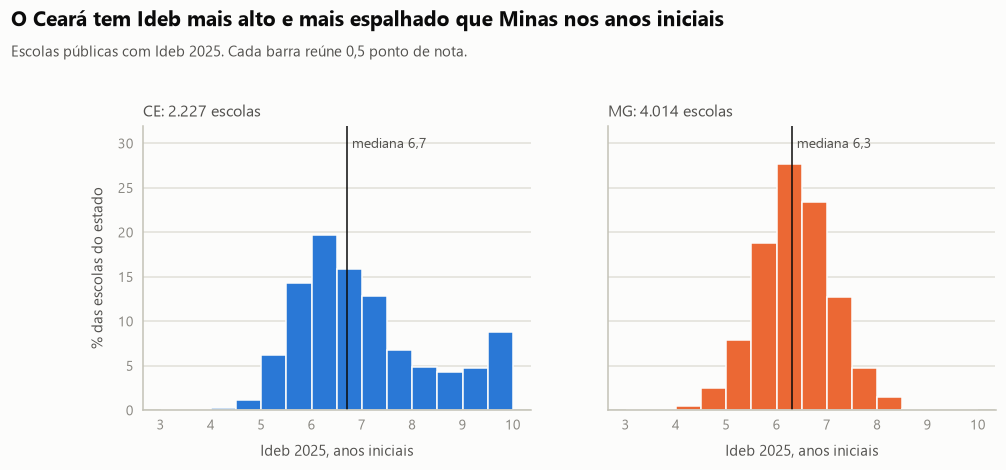

In [26]:
ideb = sql("""
    SELECT SG_UF, ideb_iniciais_2025 AS ideb
    FROM resumo_escola
    WHERE ideb_iniciais_2025 IS NOT NULL
""")
cores = {"CE": estilo.AZUL, "MG": estilo.LARANJA}
faixas = np.arange(3, 10.01, 0.5)

fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
for ax, uf in zip(eixos, ["CE", "MG"]):
    notas = ideb.loc[ideb["SG_UF"] == uf, "ideb"]
    ax.hist(notas, bins=faixas, weights=np.full(len(notas), 100 / len(notas)),
            color=cores[uf], edgecolor=estilo.SUPERFICIE, linewidth=1)
    ax.axvline(notas.median(), color=estilo.TINTA, linewidth=1)
    ax.set_ylim(0, 32)
    ax.text(notas.median() + 0.1, 29.5, f"mediana {estilo.num(notas.median(), 1)}",
            fontsize=9, color=estilo.TINTA_2)
    ax.set_title(f"{uf}: {estilo.num(len(notas), 0)} escolas", loc="left",
                 fontsize=10.5, color=estilo.TINTA_2)
    ax.set_xlabel("Ideb 2025, anos iniciais")
    ax.grid(axis="x", visible=False)

eixos[0].set_ylabel("% das escolas do estado")
estilo.formato_br(eixos[0], "y", 0)
estilo.titulo(fig, "O Ceará tem Ideb mais alto e mais espalhado que Minas nos anos iniciais",
              "Escolas públicas com Ideb 2025. Cada barra reúne 0,5 ponto de nota.")
estilo.salva(fig, "01_distribuicao_ideb")
plt.show()

In [27]:
for uf in ["CE", "MG"]:
    notas = ideb.loc[ideb["SG_UF"] == uf, "ideb"]
    print(uf, f"mediana {notas.median():.1f} | desvio padrão {notas.std():.2f} | Ideb >= 9,5:", (notas >= 9.5).sum(), f"({100 * (notas >= 9.5).mean():.1f}%)",
          "| >= 9,0:", (notas >= 9.0).sum(), f"({100 * (notas >= 9.0).mean():.1f}%)",
          "| >= 8,0:", f"{100 * (notas >= 8.0).mean():.1f}%")

CE mediana 6.7 | desvio padrão 1.34 | Ideb >= 9,5: 197 (8.8%) | >= 9,0: 303 (13.6%) | >= 8,0: 22.7%
MG mediana 6.3 | desvio padrão 0.74 | Ideb >= 9,5: 0 (0.0%) | >= 9,0: 1 (0.0%) | >= 8,0: 1.7%


As barras de Minas se concentram entre 5,5 e 7,5. As do Ceará se abrem para a direita e formam uma segunda elevação perto do teto de 10: 197 escolas (8,8%) com Ideb de 9,5 ou mais, contra nenhuma em Minas. O Ceará tem 22,7% das escolas com Ideb de 8,0 ou mais, e Minas tem 1,7%. A diferença entre as médias é de 0,69 e a das medianas é de 0,4 (6,7 contra 6,3), o que é típico de uma cauda longa à direita.

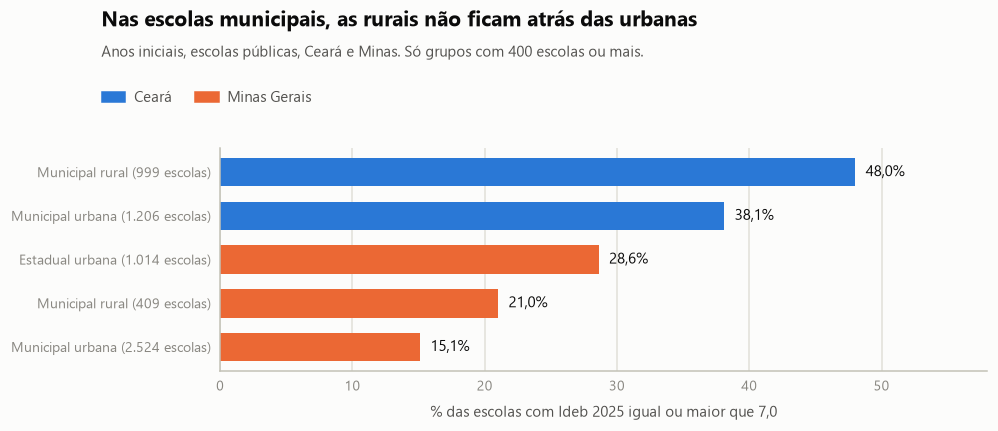

In [28]:
fig, ax = plt.subplots(figsize=(9, 3.8))
plot = rede.iloc[::-1]
rotulos = [f"{r.tipo} ({estilo.num(r.escolas, 0)} escolas)" for r in plot.itertuples()]
ax.barh(rotulos, plot["pct_alto"], color=[cores[uf] for uf in plot["SG_UF"]], height=0.65)

for y, valor in enumerate(plot["pct_alto"]):
    ax.text(valor + 0.8, y, f"{estilo.num(valor, 1)}%", va="center", fontsize=9.5, color=estilo.TINTA)

ax.set_xlim(0, 58)
ax.grid(axis="y", visible=False)
ax.set_xlabel("% das escolas com Ideb 2025 igual ou maior que 7,0")
estilo.formato_br(ax, "x", 0)
estilo.titulo(fig, "Nas escolas municipais, as rurais não ficam atrás das urbanas",
              "Anos iniciais, escolas públicas, Ceará e Minas. Só grupos com 400 escolas ou mais.", topo=1.35)
estilo.legenda_figura(fig, [Patch(color=cores["CE"], label="Ceará"),
                            Patch(color=cores["MG"], label="Minas Gerais")], ncol=2)
estilo.salva(fig, "02_ideb_alto_por_tipo_de_escola")
plt.show()

O gráfico repete a tabela de rede e localização. Entre as municipais, as rurais têm parcela maior de Ideb alto que as urbanas nos dois estados, e as estaduais urbanas de Minas ficam acima das municipais do mesmo estado.

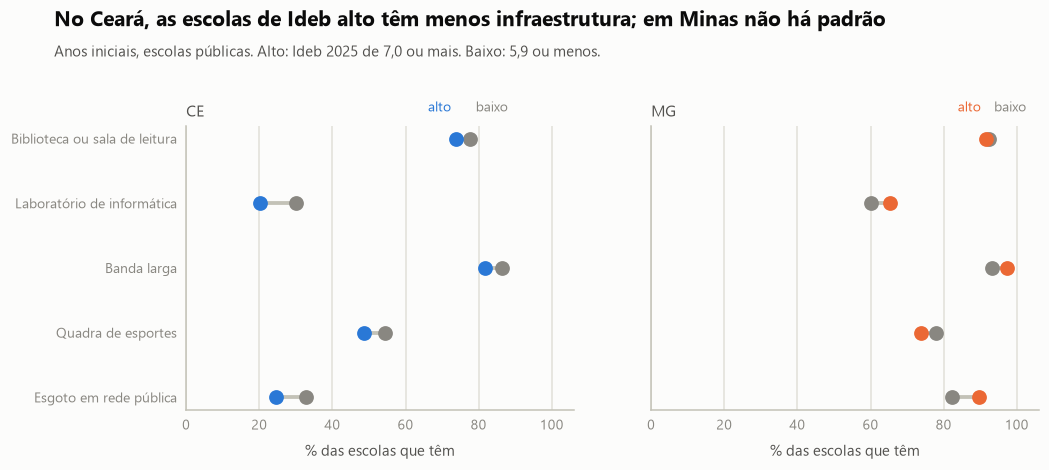

In [29]:
itens = {
    "biblioteca": "Biblioteca ou sala de leitura",
    "lab_informatica": "Laboratório de informática",
    "banda_larga": "Banda larga",
    "quadra": "Quadra de esportes",
    "esgoto_rede": "Esgoto em rede pública",
}

fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
for ax, uf in zip(eixos, ["CE", "MG"]):
    d = infra[infra["SG_UF"] == uf].set_index("grupo")
    for y, coluna in enumerate(itens):
        baixo, alto = d.loc["baixo", coluna], d.loc["alto", coluna]
        ax.plot([baixo, alto], [y, y], color=estilo.EIXO, linewidth=2.5, zorder=1)
        ax.scatter(baixo, y, s=75, color=estilo.TINTA_3, zorder=3)
        ax.scatter(alto, y, s=75, color=cores[uf], zorder=3)
        if y == 0:
            menor, maior = sorted([(baixo, "baixo", estilo.TINTA_3), (alto, "alto", cores[uf])])
            ax.text(menor[0] - 1.5, y - 0.42, menor[1], ha="right", fontsize=9, color=menor[2])
            ax.text(maior[0] + 1.5, y - 0.42, maior[1], ha="left", fontsize=9, color=maior[2])
    ax.set_yticks(range(len(itens)))
    ax.set_yticklabels(itens.values())
    ax.set_xlim(0, 106)
    ax.set_xticks(range(0, 101, 20))
    ax.set_title(uf, loc="left", fontsize=10.5, color=estilo.TINTA_2)
    ax.set_xlabel("% das escolas que têm")
    ax.grid(axis="y", visible=False)

eixos[0].invert_yaxis()
estilo.titulo(fig, "No Ceará, as escolas de Ideb alto têm menos infraestrutura; em Minas não há padrão",
              "Anos iniciais, escolas públicas. Alto: Ideb 2025 de 7,0 ou mais. Baixo: 5,9 ou menos.")
estilo.salva(fig, "03_infraestrutura_alto_baixo")
plt.show()

No Ceará, o ponto do grupo alto fica à esquerda do baixo nos cinco itens. Em Minas, três itens têm o grupo alto à frente (laboratório de informática, banda larga e esgoto) e dois atrás (biblioteca e quadra), com diferenças pequenas.

## O que ficou

Nos anos iniciais de Minas e Ceará, nem o tamanho da escola, nem o número de alunos por turma, nem a formação dos docentes, nem a infraestrutura separam as escolas de Ideb alto das de Ideb baixo de forma igual nos dois estados. No Ceará, o grupo alto tem escolas menores e com menos infraestrutura. A diferença entre os estados aparece mais na distribuição do que na média, por causa de um grupo de escolas cearenses com nota próxima do teto. O banco mostra isso e não explica a causa.

In [30]:
con.close()